In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Dataset Loading (Synthetic)

In [2]:
synthetic_train = pd.read_csv('anthrax_decision_support_data.csv')
synthetic_train.head()

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,0,0,0,1,1,1,1,0,0,1,0,1,0,1,0
1,1,0,0,1,1,0,0,1,0,1,0,1,0,1,1
2,1,0,1,1,1,0,0,0,1,0,1,0,0,0,1
3,1,0,1,1,1,0,1,1,0,1,0,0,0,1,1
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


### Duplication Check and Removal

In [3]:
# duplicate data
duplicate_data = synthetic_train.duplicated().sum()
print(duplicate_data)

176


In [4]:
synthetic_train = synthetic_train.drop_duplicates()

### Class Balance - Check

In [5]:
print(synthetic_train['Anthrax'].value_counts())

Anthrax
0    424
1    400
Name: count, dtype: int64


In [6]:
field_test = pd.read_csv("Anthrax field data updated.csv")
field_test.head(3)

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,1,1,0,1,1,0,0,0,1,0,1,0,1,1,1
1,1,1,1,1,0,0,0,0,1,0,1,0,0,1,1
2,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1


In [7]:
synthetic_train[synthetic_train.columns] = synthetic_train[synthetic_train.columns].astype('float64')

In [8]:
field_test[field_test.columns] = field_test[field_test.columns].astype('float64')

### Model Part

In [9]:
x = synthetic_train.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y = synthetic_train.iloc[: , -1]

In [10]:
x_test = field_test.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y_test = field_test.iloc[: , -1]

In [ ]:
from sklearn.model_selection import train_test_split
# split is done to check the distribution shift.... full and this setup both are analyzed but testing data is always kept field collected data.
x_train, x_dev, y_train, y_dev = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Don't Run the Exact Below Cell

In [ ]:
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters Found: {'classifier__C': np.float64(5.934145688620425), 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best Cross-Validation Roc-AUC: 0.9714289215686275

### Model Code

In [12]:
from sklearn.linear_model import LogisticRegression
# using cv = 5
logistic = LogisticRegression(
    C = 5.93,
    class_weight = None,
    penalty = "l1",
    solver = "liblinear",
    random_state = 42)

In [13]:
logistic.fit(x_train, y_train)

LogisticRegression(C=5.93, penalty='l1', random_state=42, solver='liblinear')

In [14]:
y_prob = logistic.predict_proba(x_test)[:, 1]

In [62]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = (y_prob >= 0.50).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.61      0.76        31
         1.0       0.60      1.00      0.75        18

    accuracy                           0.76        49
   macro avg       0.80      0.81      0.76        49
weighted avg       0.85      0.76      0.76        49

[[19 12]
 [ 0 18]]


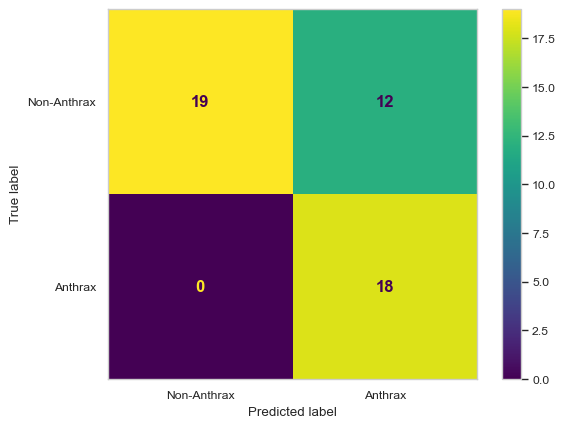

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=["Non-Anthrax", "Anthrax"],
    text_kw={"fontsize": 12, "weight": "bold"}
)

plt.grid(False)

plt.show()

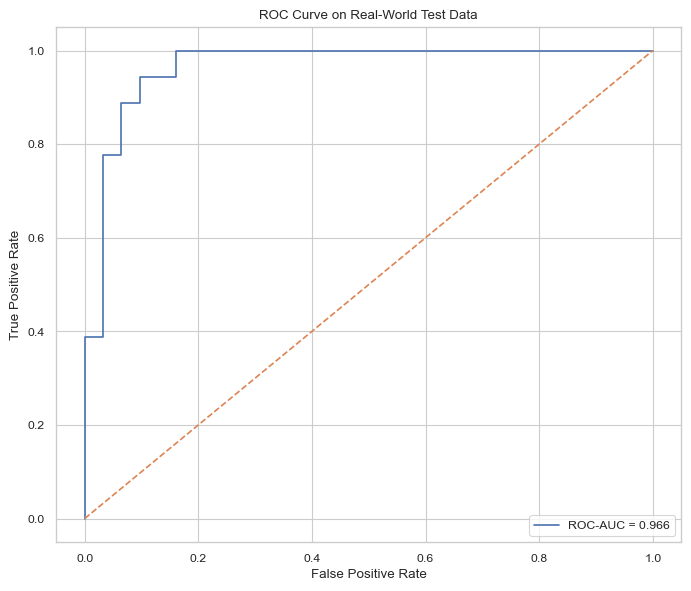

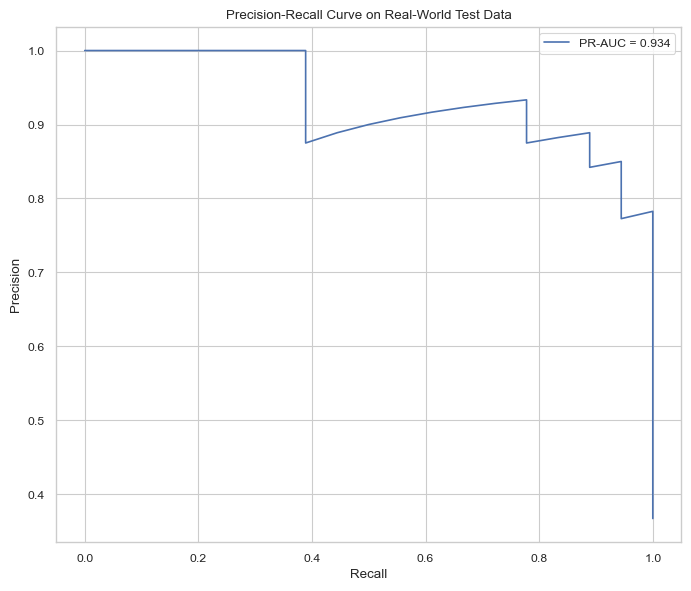

ROC-AUC: 0.966
PR-AUC:  0.934


In [ ]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Predicted probabilities on real-world test data
y_prob_real = logistic.predict_proba(x_test)[:, 1]

# ROC-AUC

fpr, tpr, _ = roc_curve(y_test, y_prob_real)
roc_auc = roc_auc_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()

# PR-AUC

precision, recall, _ = precision_recall_curve(y_test, y_prob_real)
pr_auc = average_precision_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")

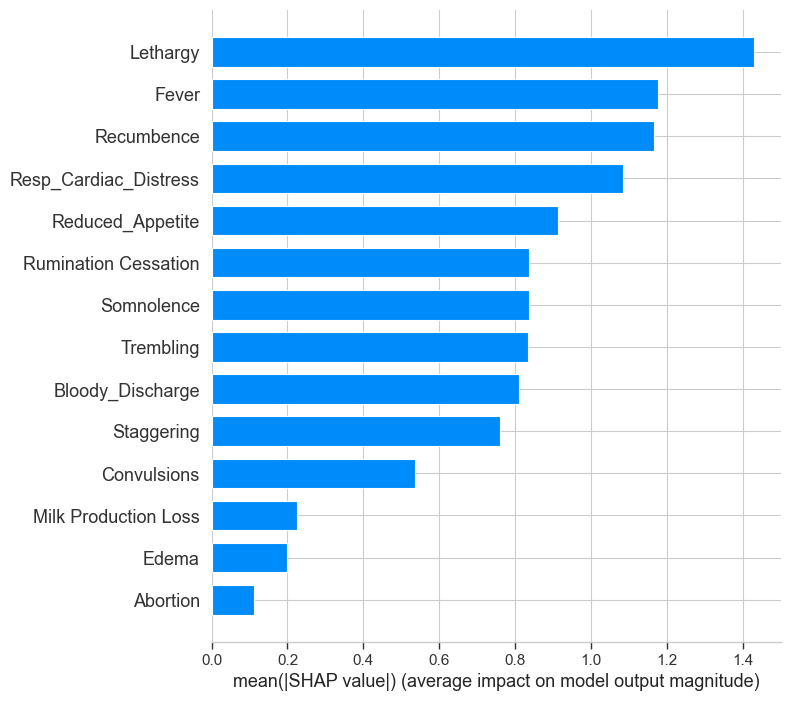

In [55]:
import shap

explainer = shap.Explainer(logistic, x_train)

# SHAP values
shap_values = explainer(x_test)

# Global summary plot
shap.summary_plot(
    shap_values,
    x_test,
    plot_type="bar"
)

In [19]:
y_prob_syn = logistic.predict_proba(x_dev)[:, 1]
y_prob_real = logistic.predict_proba(x_test)[:, 1]

In [31]:
np.sum(y_prob_real[y_test == 0] >= 0.5)

np.int64(12)

### Distribution Shift Checking

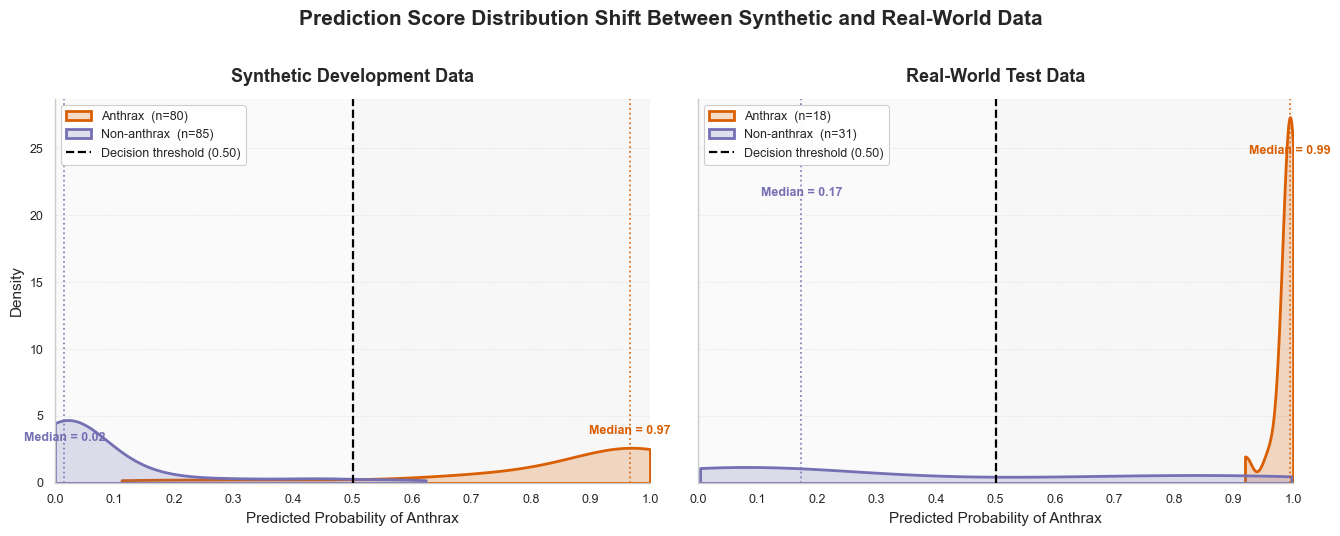

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper")

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
threshold = 0.5

colors = {
    "Anthrax": "#D95F02",
    "Non-anthrax": "#7570B3"
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.2),
    sharex=True,
    sharey=True
)

# ---------------------------------------------------------
# Support counts
# ---------------------------------------------------------
n_syn_pos = np.sum(y_dev == 1)
n_syn_neg = np.sum(y_dev == 0)

n_real_pos = np.sum(y_test == 1)
n_real_neg = np.sum(y_test == 0)


# ---------------------------------------------------------
# Helper function
# ---------------------------------------------------------
def plot_distribution(ax, probs, labels, title, n_pos, n_neg):

    pos = probs[labels == 1]
    neg = probs[labels == 0]

    # -----------------------------------------------------
    # KDEs
    # Same bandwidth for both datasets/classes
    # to preserve comparability
    # -----------------------------------------------------
    sns.kdeplot(
        pos,
        ax=ax,
        fill=True,
        color=colors["Anthrax"],
        alpha=0.22,
        linewidth=2.0,
        bw_adjust=1.0,
        cut=0,
        clip=(0, 1),
        label=f"Anthrax  (n={n_pos:,})"
    )

    sns.kdeplot(
        neg,
        ax=ax,
        fill=True,
        color=colors["Non-anthrax"],
        alpha=0.22,
        linewidth=2.0,
        bw_adjust=1.0,
        cut=0,
        clip=(0, 1),
        label=f"Non-anthrax  (n={n_neg:,})"
    )

    # -----------------------------------------------------
    # Decision regions
    # -----------------------------------------------------
    ax.axvspan(
        0,
        threshold,
        color="gray",
        alpha=0.035,
        zorder=0
    )

    ax.axvspan(
        threshold,
        1,
        color="gray",
        alpha=0.06,
        zorder=0
    )

    # -----------------------------------------------------
    # Classification threshold
    # -----------------------------------------------------
    ax.axvline(
        threshold,
        color="black",
        linestyle="--",
        linewidth=1.6,
        zorder=5,
        label="Decision threshold (0.50)"
    )

    # -----------------------------------------------------
    # Median prediction scores
    # -----------------------------------------------------
    pos_median = np.median(pos)
    neg_median = np.median(neg)

    ax.axvline(
        pos_median,
        color=colors["Anthrax"],
        linestyle=":",
        linewidth=1.3,
        alpha=0.85
    )

    ax.axvline(
        neg_median,
        color=colors["Non-anthrax"],
        linestyle=":",
        linewidth=1.3,
        alpha=0.85
    )

    # -----------------------------------------------------
    # Median annotations
    # -----------------------------------------------------
    ymax = ax.get_ylim()[1]

    ax.text(
        pos_median,
        ymax * 0.88,
        f"Median = {pos_median:.2f}",
        color=colors["Anthrax"],
        fontsize=9,
        ha="center",
        va="top",
        fontweight="bold"
    )

    ax.text(
        neg_median,
        ymax * 0.77,
        f"Median = {neg_median:.2f}",
        color=colors["Non-anthrax"],
        fontsize=9,
        ha="center",
        va="top",
        fontweight="bold"
    )

    # -----------------------------------------------------
    # Titles and labels
    # -----------------------------------------------------
    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Predicted Probability of Anthrax",
        fontsize=11
    )

    ax.set_ylabel(
        "Density",
        fontsize=11
    )

    # -----------------------------------------------------
    # Axis formatting
    # -----------------------------------------------------
    ax.set_xlim(0, 1)

    ax.set_xticks(
        np.arange(0, 1.01, 0.1)
    )

    ax.tick_params(
        axis="both",
        labelsize=9
    )

    # -----------------------------------------------------
    # Grid
    # -----------------------------------------------------
    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.6,
        alpha=0.35
    )

    ax.grid(
        axis="x",
        visible=False
    )

    # -----------------------------------------------------
    # Spines
    # -----------------------------------------------------
    sns.despine(
        ax=ax,
        top=True,
        right=True
    )

    # -----------------------------------------------------
    # Legend
    # -----------------------------------------------------
    ax.legend(
        loc="upper left",
        frameon=True,
        framealpha=0.95,
        facecolor="white",
        edgecolor="0.8",
        fontsize=9
    )


# ---------------------------------------------------------
# Synthetic data
# ---------------------------------------------------------
plot_distribution(
    axes[0],
    y_prob_syn,
    y_dev,
    "Synthetic Development Data",
    n_syn_pos,
    n_syn_neg
)

# ---------------------------------------------------------
# Real-world data
# ---------------------------------------------------------
plot_distribution(
    axes[1],
    y_prob_real,
    y_test,
    "Real-World Test Data",
    n_real_pos,
    n_real_neg
)


# ---------------------------------------------------------
# Overall title
# ---------------------------------------------------------
fig.suptitle(
    "Prediction Score Distribution Shift Between Synthetic and Real-World Data",
    fontsize=15,
    fontweight="bold",
    y=1.02
)


# ---------------------------------------------------------
# Shared y-axis formatting
# ---------------------------------------------------------
axes[0].set_ylabel("Density", fontsize=11)
axes[1].set_ylabel("")


plt.tight_layout()

plt.show()

### Hyper Para Tuning

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipeline = Pipeline([
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

In [13]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import uniform

param_dist = {
    'classifier__C': uniform(0.01, 10),
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear'],
    'classifier__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=2,
    random_state=42,
    return_train_score=True
)

random_search.fit(x, y)

print("Best Parameters Found:", random_search.best_params_)
print("Best Cross-Validation Roc-AUC:", random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters Found: {'classifier__C': np.float64(5.934145688620425), 'classifier__class_weight': None, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best Cross-Validation Roc-AUC: 0.9714289215686275
